# 01 ? Data Exploration

## ChronoTunnel: NYC Subway Ridership Intelligence

Exploratory inspection of the processed MTA subway ridership datasets.

**Coverage:** January 2020 ? December 2024  
**Source:** MTA Subway Hourly Ridership, NYC Open Data

### Objectives
- Inspect dataset schemas, dimensions, and data types.
- Assess missing values and duplicate records.
- Examine ridership and transfer distributions.
- Understand borough and transit-mode coverage.
- Record preliminary observations.

Production transformations and validation remain in `src/chronotunnel/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "processed"

HOURLY_PATH = DATA_DIR / "hourly_ridership_sample_station_level_2020_2024.csv"
MONTHLY_PATH = DATA_DIR / "monthly_ridership_station_level_2020_2024.csv"
COORDINATES_PATH = DATA_DIR / "station_coordinates.csv"

for path in [HOURLY_PATH, MONTHLY_PATH, COORDINATES_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Dataset not found: {path}")

print("Project root:", PROJECT_ROOT)
print("Data directory:", DATA_DIR)

Project root: D:\ChronoTunnel
Data directory: D:\ChronoTunnel\data\processed


## 1. Load the datasets

The hourly dataset contains selected sampled dates. The monthly dataset covers the complete monthly analytical period. Station coordinates provide geographic reference information.

Ridership and transfers are separate measures.

In [2]:
hourly = pd.read_csv(HOURLY_PATH, parse_dates=["transit_timestamp"])
monthly = pd.read_csv(MONTHLY_PATH)
coordinates = pd.read_csv(COORDINATES_PATH)

datasets = {
    "Hourly ridership": hourly,
    "Monthly ridership": monthly,
    "Station coordinates": coordinates,
}

for name, frame in datasets.items():
    print(f"\n{name}: {frame.shape[0]:,} rows ? {frame.shape[1]} columns")
    display(frame.head(3))


Hourly ridership: 1,172,916 rows ? 10 columns


,transit_timestamp,transit_mode,station_complex_id,station_complex,borough,latitude,longitude,ridership,transfers,source_coordinate_variants
0,2020-01-11,subway,1,"Astoria-Ditmars Blvd (N,W)",Queens,40.775036,-73.91203,91,0,1
1,2020-01-11,subway,10,"49 St (N,R,W)",Manhattan,40.759900,-73.98414,540,0,1
2,2020-01-11,subway,100,"Hewes St (M,J)",Brooklyn,40.706870,-73.95343,50,6,1



Monthly ridership: 25,679 rows ? 10 columns


,month,transit_mode,station_complex_id,station_complex,borough,latitude,longitude,ridership,transfers,source_rows
0,2020-01-01T00:00:00.000,subway,1,"Astoria-Ditmars Blvd (N,W)",Queens,40.775036,-73.91203,438897,13836,1
1,2020-01-01T00:00:00.000,subway,10,"49 St (N,R,W)",Manhattan,40.759900,-73.98414,556570,1414,1
2,2020-01-01T00:00:00.000,subway,100,"Hewes St (M,J)",Brooklyn,40.706870,-73.95343,94166,4807,1



Station coordinates: 429 rows ? 8 columns


,station_complex_id,transit_mode,station_complex,borough,latitude,longitude,total_ridership,coordinate_variants
0,1,subway,"Astoria-Ditmars Blvd (N,W)",Queens,40.775036,-73.91203,14028477,1
1,10,subway,"49 St (N,R,W)",Manhattan,40.759900,-73.98414,21320687,1
2,100,subway,"Hewes St (M,J)",Brooklyn,40.706870,-73.95343,2836174,1


## 2. Schema and data types

Inspect inferred data types, non-null counts, and missing values.

In [3]:
for name, frame in datasets.items():
    print(f"\n{name}")
    schema = pd.DataFrame(
        {
            "data_type": frame.dtypes.astype(str),
            "non_null_count": frame.notna().sum(),
            "missing_count": frame.isna().sum(),
        }
    )
    display(schema)


Hourly ridership


,data_type,non_null_count,missing_count
transit_timestamp,datetime64[us],1172916,0
transit_mode,str,1172916,0
station_complex_id,str,1172916,0
station_complex,str,1172916,0
borough,str,1172916,0
latitude,float64,1172916,0
longitude,float64,1172916,0
ridership,int64,1172916,0
transfers,int64,1172916,0
source_coordinate_variants,int64,1172916,0



Monthly ridership


,data_type,non_null_count,missing_count
month,str,25679,0
transit_mode,str,25679,0
station_complex_id,str,25679,0
station_complex,str,25679,0
borough,str,25679,0
latitude,float64,25679,0
longitude,float64,25679,0
ridership,int64,25679,0
transfers,int64,25679,0
source_rows,int64,25679,0



Station coordinates


,data_type,non_null_count,missing_count
station_complex_id,str,429,0
transit_mode,str,429,0
station_complex,str,429,0
borough,str,429,0
latitude,float64,429,0
longitude,float64,429,0
total_ridership,int64,429,0
coordinate_variants,int64,429,0


## 3. Descriptive statistics

Review numerical distributions and categorical coverage.

In [4]:
for name, frame in datasets.items():
    print(f"\n{name}: numerical summary")
    display(frame.describe().T)

    categorical = frame.select_dtypes(include=["object", "category"])
    if not categorical.empty:
        print(f"{name}: categorical cardinality")
        display(categorical.nunique().rename("unique_values").to_frame())


Hourly ridership: numerical summary


,count,mean,min,25%,50%,75%,max,std
transit_timestamp,1172916,2022-07-14 02:58:14.607286,2020-01-11 00:00:00,2021-05-12 01:00:00,2022-07-16 10:00:00,2023-10-11 16:00:00,2024-12-14 23:00:00,NaN
latitude,1172916.0,40.730646,40.576126,40.675377,40.72028,40.79164,40.903126,0.079468
longitude,1172916.0,-73.933476,-74.07484,-73.980354,-73.94425,-73.89775,-73.7554,0.057061
ridership,1172916.0,266.626759,1.0,31.0,103.0,273.0,26486.0,578.98389
transfers,1172916.0,10.54381,0.0,0.0,1.0,8.0,2432.0,41.958655
source_coordinate_variants,1172916.0,1.035192,1.0,1.0,1.0,1.0,6.0,0.219975


Hourly ridership: categorical cardinality


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_10944\92278636.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = frame.select_dtypes(include=["object", "category"])


,unique_values
transit_mode,3
station_complex_id,428
station_complex,428
borough,5



Monthly ridership: numerical summary


... (5 outputs left out)

,count,mean,std,min,25%,50%,75%,max
latitude,429.0,4.072966e+01,8.009246e-02,40.576126,4.067477e+01,4.071932e+01,4.079060e+01,4.090313e+01
longitude,429.0,-7.393368e+01,5.759538e-02,-74.074840,-7.398031e+01,-7.394489e+01,-7.389775e+01,-7.375540e+01
total_ridership,429.0,1.119502e+07,1.516579e+07,2.000000,3.894385e+06,6.613569e+06,1.237362e+07,1.682022e+08
coordinate_variants,429.0,1.139860e+00,6.725742e-01,1.000000,1.000000e+00,1.000000e+00,1.000000e+00,8.000000e+00


Station coordinates: categorical cardinality


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_10944\92278636.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = frame.select_dtypes(include=["object", "category"])


,unique_values
station_complex_id,428
transit_mode,3
station_complex,428
borough,5


## 4. Data quality assessment

This is an exploratory overview. The production validation suite in `src/chronotunnel/data/validate.py` remains the authoritative validation workflow.

In [5]:
quality_summary = pd.DataFrame(
    [
        {
            "dataset": name,
            "rows": len(frame),
            "columns": len(frame.columns),
            "missing_cells": int(frame.isna().sum().sum()),
            "duplicate_rows": int(frame.duplicated().sum()),
        }
        for name, frame in datasets.items()
    ]
)

display(quality_summary)

print("Hourly timestamp range:")
print(hourly["transit_timestamp"].min(), "to", hourly["transit_timestamp"].max())

monthly["month"] = pd.to_datetime(monthly["month"], errors="raise")
print("\nMonthly coverage:")
print(monthly["month"].min(), "to", monthly["month"].max())

,dataset,rows,columns,missing_cells,duplicate_rows
0,Hourly ridership,1172916,10,0,0
1,Monthly ridership,25679,10,0,0
2,Station coordinates,429,8,0,0


Hourly timestamp range:
2020-01-11 00:00:00 to 2024-12-14 23:00:00

Monthly coverage:
2020-01-01 00:00:00 to 2024-12-01 00:00:00


## 5. Analytical key checks

Station identity uses both `station_complex_id` and `transit_mode`. This avoids merging distinct transit modes solely because they share an identifier.

In [6]:
hourly_key = ["transit_timestamp", "station_complex_id", "transit_mode"]
monthly_key = ["month", "station_complex_id", "transit_mode"]
station_key = ["station_complex_id", "transit_mode"]

key_checks = pd.DataFrame(
    [
        {
            "dataset": "Hourly",
            "duplicate_key_groups": int(hourly.duplicated(hourly_key).sum()),
        },
        {
            "dataset": "Monthly",
            "duplicate_key_groups": int(monthly.duplicated(monthly_key).sum()),
        },
        {
            "dataset": "Station coordinates",
            "duplicate_key_groups": int(coordinates.duplicated(station_key).sum()),
        },
    ]
)

display(key_checks)

hourly_stations = set(map(tuple, hourly[station_key].drop_duplicates().to_numpy()))
monthly_stations = set(map(tuple, monthly[station_key].drop_duplicates().to_numpy()))
coordinate_stations = set(
    map(tuple, coordinates[station_key].drop_duplicates().to_numpy())
)

print("Hourly station-mode pairs:", len(hourly_stations))
print("Monthly station-mode pairs:", len(monthly_stations))
print("Coordinate station-mode pairs:", len(coordinate_stations))
print("Hourly pairs without coordinates:", len(hourly_stations - coordinate_stations))
print("Monthly pairs without coordinates:", len(monthly_stations - coordinate_stations))

,dataset,duplicate_key_groups
0,Hourly,0
1,Monthly,0
2,Station coordinates,0


Hourly station-mode pairs: 428
Monthly station-mode pairs: 429
Coordinate station-mode pairs: 429
Hourly pairs without coordinates: 0
Monthly pairs without coordinates: 0


## 6. Ridership and transfer distributions

The distributions may be right-skewed because station demand varies substantially. The logarithmic frequency axis helps inspect less frequent high-volume observations.

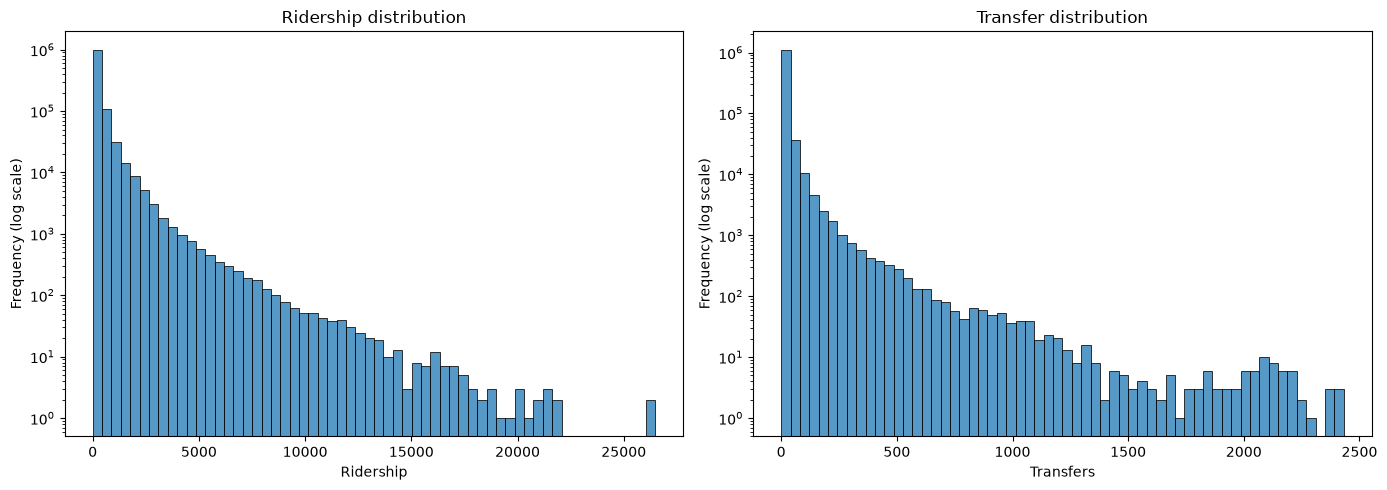

,count,mean,std,min,25%,50%,75%,90%,95%,99%,max
ridership,1172916.0,266.626759,578.983890,1.0,31.0,103.0,273.0,615.0,1001.0,2563.0,26486.0
transfers,1172916.0,10.543810,41.958655,0.0,0.0,1.0,8.0,23.0,42.0,136.0,2432.0


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, column, title in [
    (axes[0], "ridership", "Ridership distribution"),
    (axes[1], "transfers", "Transfer distribution"),
]:
    values = hourly[column].dropna()
    values = values[values >= 0]
    sns.histplot(values, bins=60, ax=ax)
    ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel(column.replace("_", " ").title())
    ax.set_ylabel("Frequency (log scale)")

plt.tight_layout()
plt.show()

display(
    hourly[["ridership", "transfers"]]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])
    .T
)

## 7. Borough and transit-mode coverage

Compare monthly ridership and transfers across boroughs and transit modes.

In [8]:
borough_summary = (
    monthly.groupby("borough", dropna=False)
    .agg(
        records=("ridership", "size"),
        total_ridership=("ridership", "sum"),
        total_transfers=("transfers", "sum"),
        station_ids=("station_complex_id", "nunique"),
    )
    .sort_values("total_ridership", ascending=False)
)

mode_summary = (
    monthly.groupby("transit_mode", dropna=False)
    .agg(
        records=("ridership", "size"),
        total_ridership=("ridership", "sum"),
        total_transfers=("transfers", "sum"),
    )
    .sort_values("total_ridership", ascending=False)
)

display(borough_summary)
display(mode_summary)

,records,total_ridership,total_transfers,station_ids
borough,,,,
Manhattan,7379,2576696612,55359465,123
Brooklyn,9359,1098172665,46569921,156
Queens,4740,734785978,69482941,79
Bronx,4080,384162750,24310041,68
Staten Island,121,8846915,2179374,2


,records,total_ridership,total_transfers
transit_mode,,,
subway,25439,4783143149,194274478
tram,120,10674858,1447890
staten_island_railway,120,8846913,2179374


## 8. Preliminary observations

After executing the notebook, document observations about:

1. Dataset sizes and coverage.
2. Missing values and duplicate analytical keys.
3. Ridership and transfer distribution shapes.
4. Borough-level demand concentration.
5. Coordinate coverage of station-mode pairs.
6. Questions that require deeper temporal or statistical analysis.

### Interpretation cautions

- The hourly dataset contains 120 sampled dates, not every hour from 2020?2024.
- Monthly records cover the full 60-month period.
- Coordinates are representative geographic positions, not necessarily station entrances.
- Transfers are separate from ridership.
- Descriptive patterns do not establish causation.

### Next notebook
Continue to **02 ? Ridership Analysis** for temporal trends, station rankings, and borough-level comparisons.